# 🌐 Tema 6.3: Grafos Multiplex (Múltiples Relaciones)
Ejemplo didáctico: La Vida Universitaria.

### 1. El Problema del Grafo Simple (`nx.Graph`)
Intentemos modelar a dos estudiantes (Ana y Beto) que son compañeros de proyecto, pero que también juegan Valorant juntos en las noches.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

# Usamos el grafo tradicional que conocemos
G_simple = nx.Graph()

# Añadimos la relación académica
G_simple.add_edge('Ramiro', 'Cristobal', relacion='Proyecto Final')

# Añadimos la relación de gaming
G_simple.add_edge('Ramiro', 'Cristobal', relacion='Clash Royale')

print("Aristas en el grafo simple:")
print(G_simple.edges(data=True))

Aristas en el grafo simple:
[('Ramiro', 'Cristobal', {'relacion': 'Clash Royale'})]


### 2. La Solución: MultiGraph (El Grafo Multicapa)
Para modelar la complejidad humana, usamos `nx.MultiGraph`, que permite múltiples aristas paralelas entre los mismos dos nodos.

In [2]:
# Instanciamos un Multigrafo
MG = nx.MultiGraph()

# Poblamos nuestro microcosmos universitario
MG.add_edge('Ramiro', 'Cristobal', relacion='Proyecto Final')
MG.add_edge('Ramiro', 'Cristobal', relacion='Clash Royale')
MG.add_edge('Beto', 'Carlos', relacion='Roomies')
MG.add_edge('Beto', 'Carlos', relacion='Clash Royale')
MG.add_edge('Carlos', 'Dani', relacion='Proyecto Final')

print("\n--- Todas las relaciones entre Ramiro y Cristobal ---")
display(MG['Ramiro']['Cristobal'])

print("\nNodos totales:", MG.number_of_nodes())
print("Aristas totales:", MG.number_of_edges())


--- Todas las relaciones entre Ramiro y Cristobal ---


AtlasView({0: {'relacion': 'Proyecto Final'}, 1: {'relacion': 'Clash Royale'}})


Nodos totales: 5
Aristas totales: 5


### 3. Diseccionando el Grafo (Slicing)
Si queremos saber quién es el mejor jugando Valorant, la relación de 'Roomies' o 'Proyecto' solo nos hace ruido. Debemos extraer (rebanar) esa capa específica.

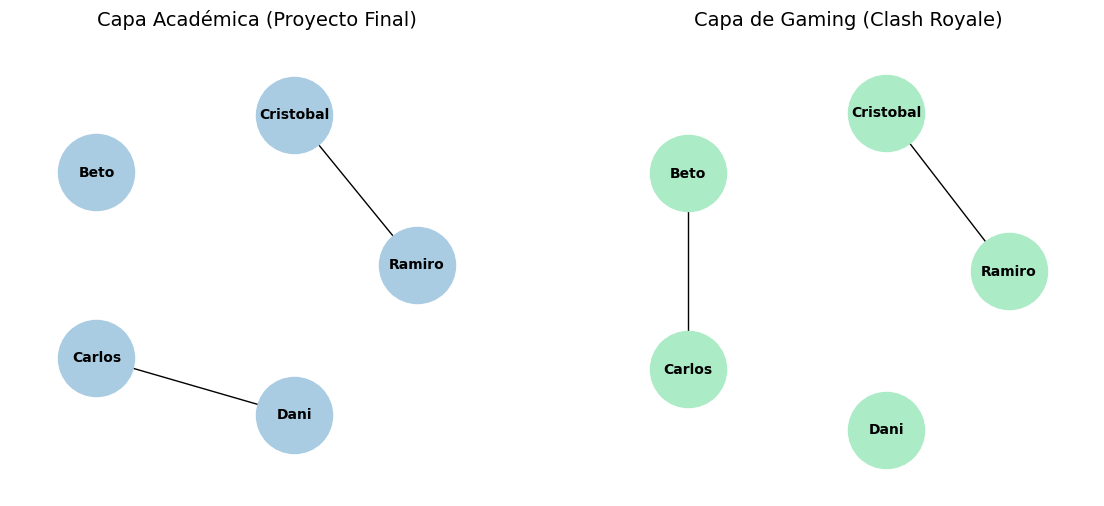

In [3]:
# Extraemos las capas
aristas_academicas = [(u, v) for u, v, d in MG.edges(data=True) if d['relacion'] == 'Proyecto Final']
G_academico = nx.Graph()
G_academico.add_nodes_from(MG.nodes()) # Aseguramos que todos los nodos existan aunque no tengan aristas aquí
G_academico.add_edges_from(aristas_academicas)

aristas_gaming = [(u, v) for u, v, d in MG.edges(data=True) if d['relacion'] == 'Clash Royale']
G_gaming = nx.Graph()
G_gaming.add_nodes_from(MG.nodes())
G_gaming.add_edges_from(aristas_gaming)

# 🛠️ EL TRUCO VISUAL PARA MULTIGRAFOS: 
# Calculamos la posición (pos) UNA SOLA VEZ basándonos en los 4 nodos. 
# circular_layout los pone en un cuadrado perfecto, evitando que se aglomeren.
pos_fija = nx.circular_layout(MG)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
# Usamos la 'pos_fija' y ajustamos márgenes para que los nodos no se corten en los bordes
nx.draw(G_academico, pos_fija, with_labels=True, node_color='#A9CCE3', node_size=3000, font_weight='bold', font_size=10)
plt.title('Capa Académica (Proyecto Final)', fontsize=14)
plt.margins(0.2) # Da un 20% de espacio extra en los bordes

plt.subplot(1, 2, 2)
nx.draw(G_gaming, pos_fija, with_labels=True, node_color='#ABEBC6', node_size=3000, font_weight='bold', font_size=10)
plt.title('Capa de Gaming (Clash Royale)', fontsize=14)
plt.margins(0.2)

plt.show()

# Desmantelando la Red Multiplex


Contexto de Negocio (El Ciberataque): Han sido llamados de emergencia por la junta directiva de la red social corporativa. Una granja de trolls organizada está saboteando la plataforma. A simple vista (en la red de Retweets), estos bots interactúan como personas normales, e incluso le dan Retweet a usuarios legítimos para disimular.



El equipo de ciberseguridad ha extraído un archivo crudo de la base de datos api_troll_farm.json que incluye tres dimensiones de la realidad: La interacción social, la última IP de conexión, y el hash de la tarjeta de crédito con la que pagaron su suscripción premium.

Su misión es cruzar las capas, armar el Grafo Multiplex, e identificar exactamente quiénes son los bots para banearlos y bloquear su método de pago.



## Fase 1
### 1. Abran el archivo .json usando la librería json de Python.


In [4]:
import pandas as pd
import json 

src = "./api_troll_farm.json"
with open(src, "r") as file:
    data = json.load(file)

df = pd.json_normalize(data)
print (df)
# print(df.head(100))

       account_id metadata.last_ip metadata.payment_hash  \
0     TROLL_BOT_1    104.28.19.112   VISA-4455-XXXX-9090   
1    real_user_14    189.168.1.196     MC-8573-XXXX-1111   
2    real_user_13    189.168.1.184                  None   
3     TROLL_BOT_5    104.28.19.112   VISA-4455-XXXX-9090   
4    real_user_12     189.168.1.51     MC-4432-XXXX-1111   
5    real_user_11    189.168.1.231     MC-5554-XXXX-1111   
6    real_user_15    189.168.1.186                  None   
7     real_user_8    189.168.1.246     MC-5803-XXXX-1111   
8    real_user_10     189.168.1.68                  None   
9     troll_bot_1    104.28.19.112   VISA-4455-XXXX-9090   
10    TROLL_BOT_4    104.28.19.112   VISA-4455-XXXX-9090   
11    TROLL_BOT_6    104.28.19.112   VISA-4455-XXXX-9090   
12    real_user_6     189.168.1.36     MC-2584-XXXX-1111   
13    real_user_4    189.168.1.160     MC-1106-XXXX-1111   
14    real_user_9    189.168.1.230     MC-4150-XXXX-1111   
15    real_user_1    189.168.1.238      

### 2. Extraigan los datos para construir una única tabla maestra (DataFrame) con 3 columnas: Origen, Destino y Relacion.
- Reto A (La Capa Social): Extraigan los "retweets". Si Usuario_A retuitea a Usuario_B, eso es una relación tipo "Retweet". Ignoren auto-retweets. (Ojo con las minúsculas/mayúsculas).
- Reto B (La Capa de Infraestructura): En el JSON, la IP y la Tarjeta son metadatos individuales. Deberán ingeniárselas (recomendación: extraigan los metadatos a un DataFrame y hagan un merge del dataframe consigo mismo) para conectar a los usuarios. Si Usuario_A y Usuario_B tienen la misma Tarjeta, agreguen una fila a su tabla con relación tipo "Misma_Tarjeta".

In [5]:
# Normalizamos IDs (troll_bot_1 == TROLL_BOT_1)
df['account_id'] = df['account_id'].str.upper()

# --- Reto A: Capa Social (Retweets) ---
df_social = df[['account_id', 'activity.retweets']].dropna().copy()
df_social = df_social.explode('activity.retweets')
df_social['activity.retweets'] = df_social['activity.retweets'].str.upper()
df_social = df_social[df_social['account_id'] != df_social['activity.retweets']]  # sin auto-retweets
df_social['Relacion'] = 'Retweet'
df_social = df_social.rename(columns={'account_id': 'Origen', 'activity.retweets': 'Destino'})[['Origen', 'Destino', 'Relacion']]

# --- Reto B: Capa de Infraestructura (Misma Tarjeta) ---
# dropna ANTES del merge: pandas empata NaN con NaN
df_infra = df[['account_id', 'metadata.payment_hash']].dropna().drop_duplicates()
df_cards = pd.merge(df_infra, df_infra, on='metadata.payment_hash')
df_cards = df_cards[df_cards['account_id_x'] != df_cards['account_id_y']].copy()
df_cards['Relacion'] = 'Misma_Tarjeta'
df_cards = df_cards.rename(columns={'account_id_x': 'Origen', 'account_id_y': 'Destino'})[['Origen', 'Destino', 'Relacion']]

# --- Tabla maestra ---
df_master = pd.concat([df_social, df_cards], ignore_index=True)
display(df_master)

,Origen,Destino,Relacion
0,TROLL_BOT_1,REAL_USER_11,Retweet
1,REAL_USER_14,REAL_USER_15,Retweet
2,REAL_USER_14,REAL_USER_11,Retweet
3,REAL_USER_13,REAL_USER_3,Retweet
4,REAL_USER_13,REAL_USER_9,Retweet
...,...,...,...
62,TROLL_BOT_2,TROLL_BOT_1,Misma_Tarjeta
63,TROLL_BOT_2,TROLL_BOT_5,Misma_Tarjeta
64,TROLL_BOT_2,TROLL_BOT_4,Misma_Tarjeta
65,TROLL_BOT_2,TROLL_BOT_6,Misma_Tarjeta


## Fase 2: El Grafo Multicapa 

### 1. Pasen su tabla maestra purificada a NetworkX utilizando nx.MultiDiGraph().



In [6]:
MDG = nx.from_pandas_edgelist(
    df_master,
    source='Origen',
    target='Destino',
    edge_attr='Relacion',
    create_using=nx.MultiDiGraph()
)

### 2. Comprueben que su grafo cargó correctamente imprimiendo el número total de Nodos y Aristas.

In [7]:
print("Nodos totales:", MDG.number_of_nodes())
print("Aristas totales:", MDG.number_of_edges())

Nodos totales: 21
Aristas totales: 67


## Fase 3: El Slicing Los trolls son lo suficientemente listos para esconderse en el ruido de los retweets, pero cometieron un error de novatos: todos pagaron su cuenta bot con la misma tarjeta de crédito robada.
### 1. Filtren su MultiGrafo para extraer exclusivamente las aristas cuya Relación sea "Misma_Tarjeta".


In [8]:
aristas_tarjeta = [
    (u, v) for u, v, d in MDG.edges(data=True)
    if d['Relacion'] == 'Misma_Tarjeta'
]
print(len(aristas_tarjeta), "aristas 'Misma_Tarjeta'")

30 aristas 'Misma_Tarjeta'


### 2. Metan esas aristas en un grafo no dirigido simple (nx.Graph()).


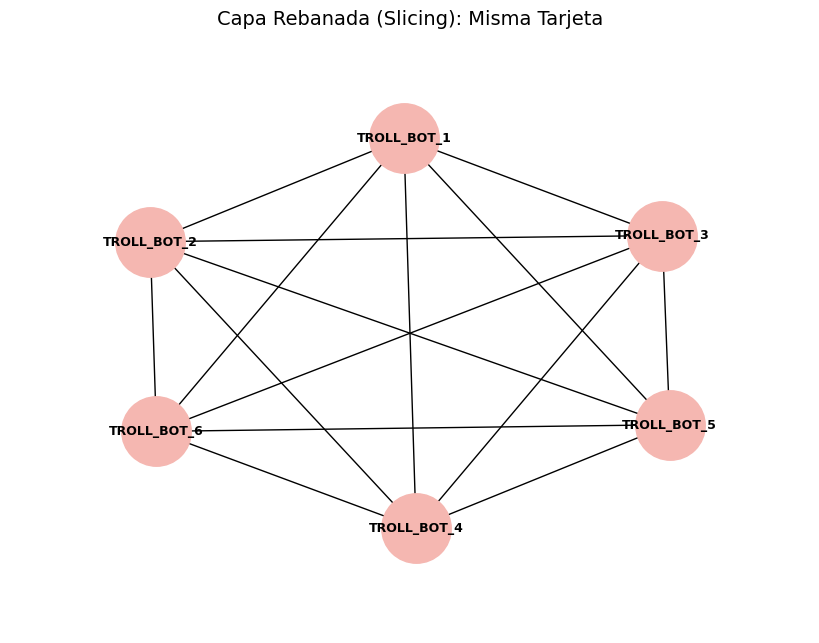

In [9]:
G_tarjeta = nx.Graph()
G_tarjeta.add_edges_from(aristas_tarjeta)

plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G_tarjeta, seed=42)
nx.draw(G_tarjeta, pos, with_labels=True, node_color='#F5B7B1', node_size=2500, font_size=9, font_weight='bold')
plt.title('Capa Rebanada (Slicing): Misma Tarjeta', fontsize=14)
plt.margins(0.2)
plt.show()

### 3. Usen la función nx.connected_components() sobre este nuevo sub-grafo para encontrar a la tribu coludida financieramente.

In [10]:
comunidades = list(nx.connected_components(G_tarjeta))
anillo_fraude = sorted(max(comunidades, key=len))
hash_tarjeta = df_infra[df_infra['account_id'].isin(anillo_fraude)]['metadata.payment_hash'].unique()

print("Comunidades:", comunidades)
print("Anillo de fraude:", anillo_fraude)
print("Hash tarjeta:", hash_tarjeta)

Comunidades: [{'TROLL_BOT_4', 'TROLL_BOT_2', 'TROLL_BOT_5', 'TROLL_BOT_3', 'TROLL_BOT_1', 'TROLL_BOT_6'}]
Anillo de fraude: ['TROLL_BOT_1', 'TROLL_BOT_2', 'TROLL_BOT_3', 'TROLL_BOT_4', 'TROLL_BOT_5', 'TROLL_BOT_6']
Hash tarjeta: ['VISA-4455-XXXX-9090']


## Veredicto
1. ¿Cuáles son los nombres exactos (account_id) de los bots que conforman el anillo de fraude?

TROLL_BOT_1, TROLL_BOT_2, TROLL_BOT_3, TROLL_BOT_4, TROLL_BOT_5 y TROLL_BOT_6 (`troll_bot_1` es un duplicado de `TROLL_BOT_1` en minúsculas).

2. ¿Cuál es el Hash de la tarjeta de crédito comprometida que el equipo de soporte técnico debe bloquear ahora mismo?
VISA-4455-XXXX-9090

3. Si tuvieran que entrenar un modelo de predicción, ¿cómo le pasarían este descubrimiento al modelo tabular (La matriz X de entrenamiento)?

Convirtiendo lo que encontramos en el grafo en columnas numéricas por usuario y agregándolas a X:
- `en_anillo_fraude`: 1 si la cuenta pertenece a la componente conexa sospechosa, 0 si no.
- `tam_componente_tarjeta`: tamaño de la componente conexa en la capa "Misma_Tarjeta" (una tarjeta normal la usa 1 persona; aquí la usan 6).
- `grado_misma_tarjeta` / `grado_misma_ip`: cuántas cuentas comparten tarjeta o IP con el usuario.
- `in_degree` / `out_degree` de la capa Retweet: para detectar actividad no orgánica (ej. bots que se retuitean entre ellos).
- Opcionalmente centralidades (PageRank, betweenness) o node embeddings (Node2Vec) como columnas extra.